# Morphological Operators

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage.morphology import skeletonize

In [22]:
img = cv2.imread("noisy_binary_image.jpg", cv2.IMREAD_GRAYSCALE)
_, binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

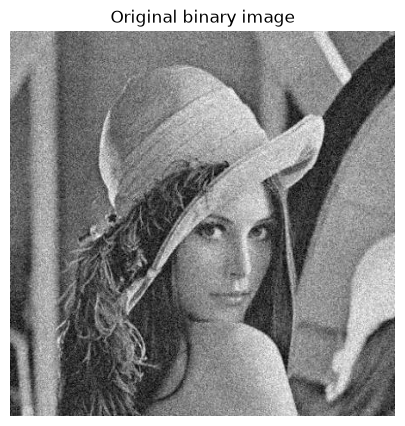

In [23]:
plt.figure(figsize=(6,5))
plt.imshow(img, cmap='gray')
plt.title('Original binary image')
plt.axis('off')
plt.show()

In [24]:
kernal = np.ones((3,3), np.uint8)
kernal_area = kernal.sum()

## 1. Erosion

In [25]:
# Manual
binary_ones = (binary/255).astype(np.float32)

In [26]:
neighborhood_sum = cv2.filter2D(binary_ones, -1, kernal)
eroded_manual = np.where(neighborhood_sum >= kernal_area - 0.5, 255, 0)
eroded_manual = eroded_manual.astype(np.uint8)

In [27]:
# auto
eroded_cv2 = cv2.erode(binary, kernal, iterations=1)

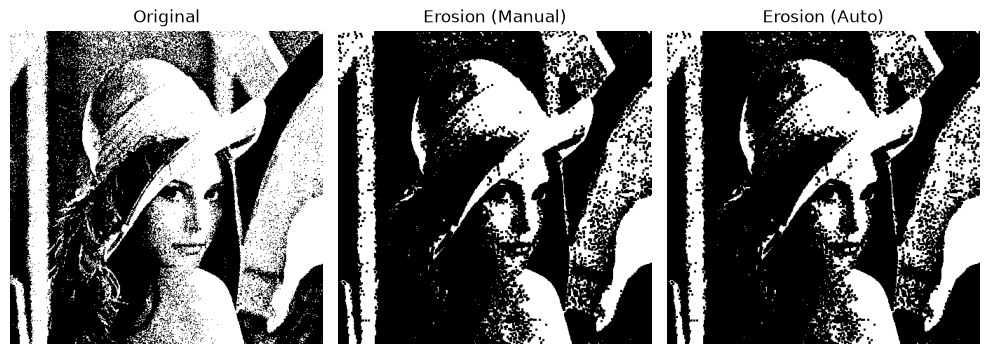

In [28]:
plt.figure(figsize=(10,5))

plt.subplot(1,3,1)
plt.imshow(binary, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(eroded_manual, cmap='gray')
plt.title('Erosion (Manual)')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(eroded_cv2, cmap='gray')
plt.title('Erosion (Auto)')
plt.axis('off')

plt.tight_layout()
plt.show()

## 2. Dilation

In [31]:
dilated_cv2 = cv2.dilate(binary, kernal, iterations=1)

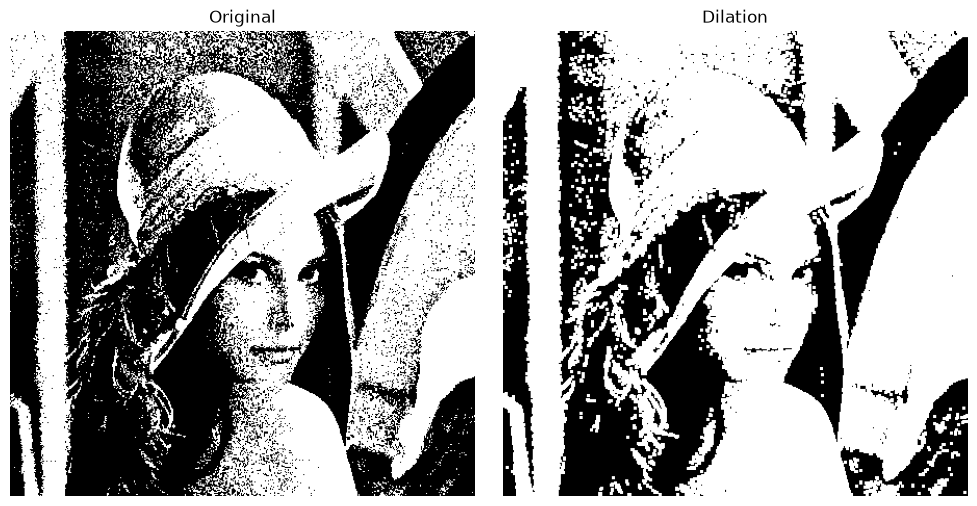

In [39]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(binary, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(dilated_cv2, cmap='gray')
plt.title('Dilation')
plt.axis('off')

plt.tight_layout()
plt.show()

## 3. Opening and Closing

In [40]:
opened_cv2 = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernal)
closed_cv2 = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernal)

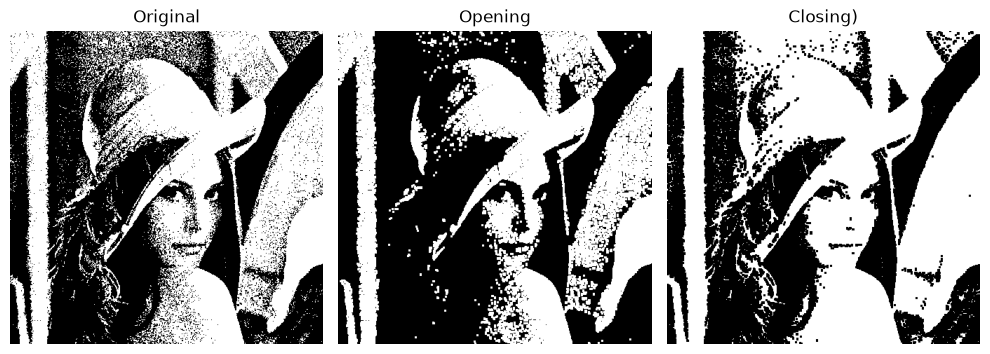

In [41]:
plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.imshow(binary, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(opened_cv2, cmap='gray')
plt.title('Opening')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(closed_cv2, cmap='gray')
plt.title('Closing)')
plt.axis('off')

plt.tight_layout()
plt.show()

## 6. Boundary Extraction

In [42]:
cleaned = opened_cv2
boundary = cv2.subtract(cleaned, cv2.erode(cleaned, kernal, iterations=1))

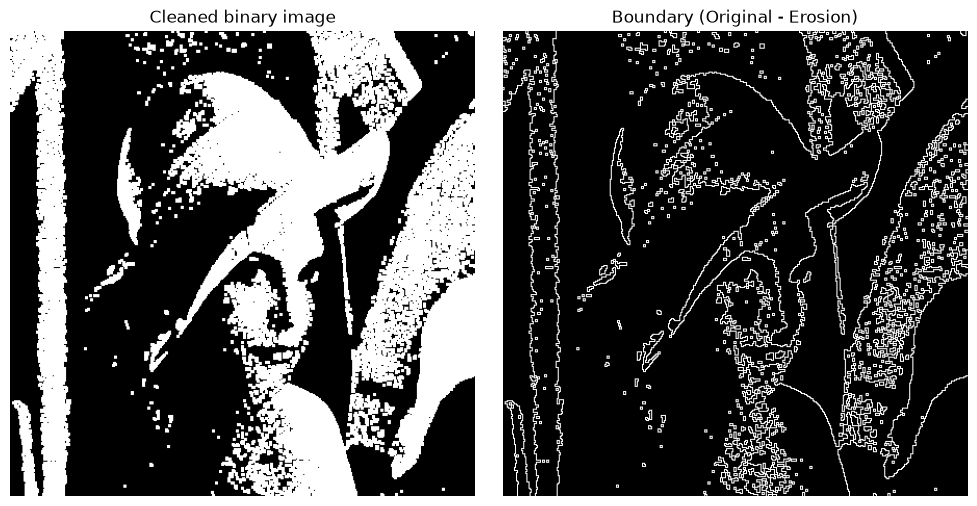

In [43]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cleaned, cmap='gray')
plt.title('Cleaned binary image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(boundary, cmap='gray')
plt.title('Boundary (Original - Erosion)')
plt.axis('off')

plt.tight_layout()
plt.show()

## 7. Thinning

In [48]:
binary_bool = cleaned > 0
skeleton = skeletonize(binary_bool)
skeleton_display = (skeleton * 255).astype(np.uint8)

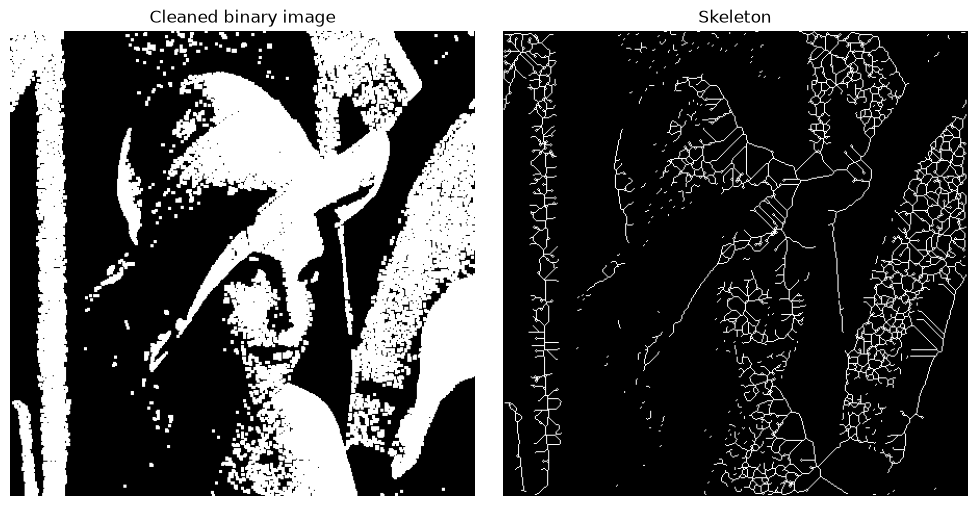

In [49]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cleaned, cmap='gray')
plt.title('Cleaned binary image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(skeleton_display, cmap='gray')
plt.title('Skeleton')
plt.axis('off')

plt.tight_layout()
plt.show()